# 01c-theory-checks: data values the Phase 1 theory note needs

The theory note compares published assumptions with this data. Seven of those
comparisons need numbers, so this notebook measures them. This corrected version
replaces the first 01c run. It does not run a
detector; that is Phase 2.

1. **Spectrum:** is the effective dimension large, as the Gaussian limits need?
2. **Temporal range:** the dependence range L chosen by the Li & Li rule.
3. **Nuisance stability:** how well can 60 volumes estimate what the stopping
   rule standardises by?
4. **Smallest detectable change:** Li & Li's Remark 3 with these estimates.
5. **Scale or structure:** is the quiet scan start a shared scale, or do the
   correlations also differ there?
6. **Noise floor:** how far apart are the correlation matrices of two adjacent
   60-volume blocks, in real scans and in no-change copies?
7. **Scan-start effect:** is it a transient or a drift, and is scale shared?

Exact-copy scans are dropped, every scan is z-scored, and labels are not read.

**To run:** attach the data, then Save & Run All. All results print here, so
the saved notebook is the only file needed.

In [1]:
import hashlib
import json
import logging
import os
import sys
import time
import traceback
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.linalg
import scipy.optimize
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 20261101
rng = np.random.default_rng(SEED)

INPUT_ROOT = Path(os.environ.get("DFCPD_INPUT", "/kaggle/input"))
WORK_ROOT = Path(os.environ.get("DFCPD_WORKING", "/kaggle/working"))
FIG = WORK_ROOT / "01c-figures"
FIG.mkdir(parents=True, exist_ok=True)

P = 105
UPPER = np.triu_indices(P, 1)
M = 60
ALPHA = 0.05
MIN_T = 180
MAX_LAG = 12
EPSILON = 0.05
GAP = 10
H_GRID = (40, 60, 80)
L_GRID = (0, 2, 4, 6, 8)
N_NUISANCE_SCANS = 100
N_SURROGATES = 3

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", stream=sys.stdout, force=True)
log = logging.getLogger("theory")
log.info("seed=%d input=%s", SEED, INPUT_ROOT)

RESULTS = {"seed": SEED, "sections_failed": []}
STATE = {}


def step(fn):
    """Run a section now, and keep going if it fails."""
    log.info("START %s", fn.__name__)
    t0 = time.time()
    try:
        fn()
        log.info("DONE  %s (%.1fs)", fn.__name__, time.time() - t0)
    except Exception:
        RESULTS["sections_failed"].append(fn.__name__)
        log.error("FAILED %s\n%s", fn.__name__, traceback.format_exc())
    return fn


BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID_INK = "#2b2b29", "#6f6e69", "#e4e2dc"
plt.rcParams.update({
    "figure.dpi": 130, "savefig.bbox": "tight", "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": GRID_INK,
    "axes.labelcolor": MUTED, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID_INK, "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False,
})


def quantiles(values, q=(.05, .25, .5, .75, .95)):
    return dict(zip([f"q{int(v * 100)}" for v in q], np.round(np.nanquantile(values, q), 4).tolist()))


def zscore(x):
    return (x - x.mean(0)) / x.std(0, ddof=1)


def phase_randomise(x, generator):
    """Surrogate with shared random phases, which keeps auto- and cross-spectra."""
    spectrum = np.fft.rfft(x - x.mean(0), axis=0)
    phases = np.exp(2j * np.pi * generator.random(spectrum.shape[0]))
    phases[0] = 1
    return np.fft.irfft(spectrum * phases[:, None], n=len(x), axis=0)


def despike(x, c=3.0):
    median = np.median(x, 0)
    mad = np.median(np.abs(x - median), 0) * 1.4826
    return np.clip(x, median - c * mad, median + c * mad)


def corr(x):
    r = np.corrcoef(x.T)
    return (r + r.T) / 2


def fisher(r):
    return np.arctanh(np.clip(r, -.999999, .999999))

2026-10-31 00:36:02,492 seed=20261101 input=/kaggle/input


In [2]:
SCANS = {}


@step
def load():
    seen = {}
    dropped = []
    for path in tqdm(sorted(INPUT_ROOT.rglob("icn_tc.npy")), desc="load"):
        x = zscore(np.load(path).astype(np.float64))
        key = hashlib.sha1(x.round(4).tobytes()).hexdigest()
        if key in seen:
            dropped.append((path.parent.name, seen[key]))
            continue
        seen[key] = path.parent.name
        SCANS[path.parent.name] = x
    lengths = pd.Series([len(x) for x in SCANS.values()]).value_counts().sort_index()
    RESULTS["scans"] = {"kept": len(SCANS), "dropped_copies": dropped, "by_T": {int(k): int(v) for k, v in lengths.items()},
                        "T_at_least_180": int(sum(len(x) >= MIN_T for x in SCANS.values()))}
    print(json.dumps(RESULTS["scans"], indent=1))


LONG = {}


@step
def long_scans():
    LONG.update({sid: x for sid, x in SCANS.items() if len(x) >= MIN_T})
    log.info("scans with T >= %d: %d", MIN_T, len(LONG))

2026-10-31 00:36:02,515 START load


load:   0%|          | 0/786 [00:00<?, ?it/s]

{
 "kept": 781,
 "dropped_copies": [
  [
   "sub269",
   "sub102"
  ],
  [
   "sub661",
   "sub512"
  ],
  [
   "sub400",
   "sub717"
  ],
  [
   "sub181",
   "sub106"
  ],
  [
   "sub303",
   "sub515"
  ]
 ],
 "by_T": {
  "100": 8,
  "134": 95,
  "204": 244,
  "208": 1,
  "210": 9,
  "230": 362,
  "234": 62
 },
 "T_at_least_180": 678
}
2026-10-31 00:36:13,553 DONE  load (11.0s)
2026-10-31 00:36:13,555 START long_scans
2026-10-31 00:36:13,556 scans with T >= 180: 678
2026-10-31 00:36:13,557 DONE  long_scans (0.0s)


## 1. Spectrum and effective dimension

Three published conditions ask for the same thing: no eigenvalue may dominate.

- Li & Li (C2) and Wang et al. A.1 need tr(S^4) = o(tr(S^2)^2).
- `d_F` = tr(S^2)^2 / tr(S^4) is the matching effective dimension, and those
  limits need it to be large.
- `r_eff` = tr(S) / ||S||_op is the Koltchinskii-Lounici effective rank.

Per-scan values use sample matrices, so they carry noise. The averaged FNC is
much less noisy, but averaging also smooths away individual structure.

In [3]:
def spectrum(r):
    eig = np.linalg.eigvalsh(r)[::-1]
    return {"lambda_1": eig[0], "r_eff": eig.sum() / eig[0], "d_F": (eig ** 2).sum() ** 2 / (eig ** 4).sum(),
            "frobenius": np.sqrt((eig ** 2).sum()), "max_abs_row_sum": np.abs(r).sum(1).max()}


@step
def effective_dimension():
    rows = [spectrum(corr(x)) for x in tqdm(LONG.values(), desc="spectrum")]
    table = pd.DataFrame(rows)
    summary = {c: quantiles(table[c]) for c in table}
    pooled = spectrum(np.mean([corr(x) for x in LONG.values()], axis=0))
    RESULTS["spectrum"] = {"per_scan": summary, "mean_correlation_matrix": {k: round(float(v), 3) for k, v in pooled.items()}}
    print(json.dumps(RESULTS["spectrum"], indent=1))

2026-10-31 00:36:13,583 START effective_dimension


spectrum:   0%|          | 0/678 [00:00<?, ?it/s]

{
 "per_scan": {
  "lambda_1": {
   "q5": 15.3024,
   "q25": 18.3052,
   "q50": 21.1096,
   "q75": 25.5439,
   "q95": 32.6837
  },
  "r_eff": {
   "q5": 3.2126,
   "q25": 4.1106,
   "q50": 4.974,
   "q75": 5.7361,
   "q95": 6.8617
  },
  "d_F": {
   "q5": 1.9709,
   "q25": 2.8774,
   "q50": 3.755,
   "q75": 4.5201,
   "q95": 5.5735
  },
  "frobenius": {
   "q5": 27.8133,
   "q25": 30.006,
   "q50": 32.0897,
   "q75": 34.7178,
   "q95": 40.0567
  },
  "max_abs_row_sum": {
   "q5": 26.8128,
   "q25": 30.5606,
   "q50": 34.0331,
   "q75": 39.2224,
   "q95": 47.0956
  }
 },
 "mean_correlation_matrix": {
  "lambda_1": 15.03,
  "r_eff": 6.986,
  "d_F": 5.232,
  "frobenius": 25.341,
  "max_abs_row_sum": 23.582
 }
}
2026-10-31 00:36:15,102 DONE  effective_dimension (1.5s)


## 2. Temporal dependence range

Li & Li estimate their range as the first lag h where
tr{C(h)C(h)'} / tr{C(0)^2} falls to 0.05, minus one. It is written L here,
because M is our training length. The estimate needs long stretches, so it is
computed on whole scans and again on the first 60 volumes.

2026-10-31 00:36:15,153 START dependence_range


range:   0%|          | 0/678 [00:00<?, ?it/s]

{
 "L_whole_scan": {
  "1": 4,
  "2": 49,
  "3": 87,
  "4": 102,
  "5": 101,
  "6": 55,
  "7": 54,
  "8": 53,
  "9": 40,
  "10": 21,
  "11": 22,
  "12": 90
 },
 "L_first_60": {
  "0": 1,
  "1": 19,
  "2": 61,
  "3": 94,
  "4": 68,
  "5": 67,
  "6": 54,
  "7": 61,
  "8": 40,
  "9": 33,
  "10": 13,
  "11": 17,
  "12": 150
 },
 "median_ratio_by_lag": [
  1.0,
  0.3793,
  0.2254,
  0.1342,
  0.0889,
  0.0674,
  0.0523,
  0.042,
  0.0367,
  0.0339,
  0.0289,
  0.0256,
  0.0237
 ]
}


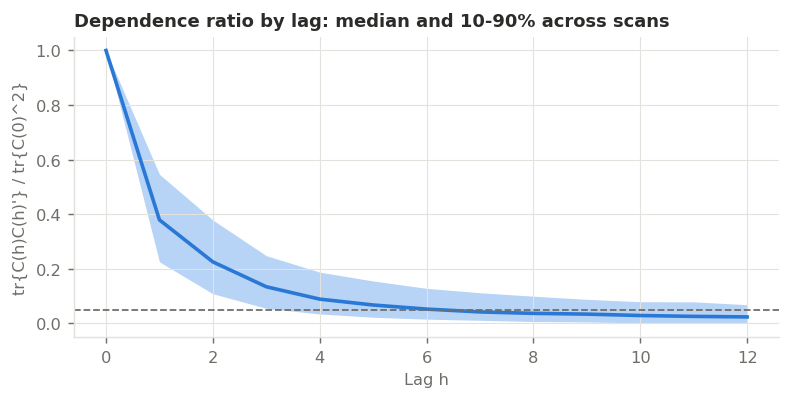

2026-10-31 00:36:29,554 DONE  dependence_range (14.4s)


In [4]:
@lru_cache(maxsize=None)
def pair_grid(T, h1, h2):
    """Pairs far enough apart that no shifted index can land on a diagonal term."""
    s, t = np.meshgrid(np.arange(T), np.arange(T), indexing="ij")
    keep = (np.abs(s - t) >= GAP + max(abs(h1), abs(h2))) & (s + h1 >= 0) & (s + h1 < T) & (t + h2 >= 0) & (t + h2 < T)
    return s[keep], t[keep]


def trace_cc(x, h1, h2, grams=None):
    """Li & Li equation (6): an estimate of tr{C(h1)C(h2)} using well-separated pairs."""
    g = x @ x.T if grams is None else grams
    s, t = pair_grid(len(x), h1, h2)
    if len(s) == 0:
        return np.nan
    return float(np.mean(g[t + h2, s] * g[s + h1, t]))


def range_estimate(x):
    g = x @ x.T
    base = trace_cc(x, 0, 0, g)
    ratios = np.array([trace_cc(x, h, -h, g) / base for h in range(MAX_LAG + 1)])
    below = np.flatnonzero(ratios <= EPSILON)
    return (int(below[0]) - 1 if len(below) else MAX_LAG), ratios


@step
def dependence_range():
    whole, block, curves = [], [], []
    for x in tqdm(LONG.values(), desc="range"):
        l_whole, ratios = range_estimate(x)
        whole.append(l_whole)
        curves.append(ratios)
        block.append(range_estimate(x[:M])[0])
    curves = np.array(curves)
    RESULTS["dependence_range"] = {
        "L_whole_scan": {int(k): int(v) for k, v in pd.Series(whole).value_counts().sort_index().items()},
        "L_first_60": {int(k): int(v) for k, v in pd.Series(block).value_counts().sort_index().items()},
        "median_ratio_by_lag": np.round(np.nanmedian(curves, axis=0), 4).tolist(),
    }
    print(json.dumps(RESULTS["dependence_range"], indent=1))
    STATE["L"] = int(np.median(whole))

    fig, ax = plt.subplots(figsize=(7, 3))
    lags = np.arange(MAX_LAG + 1)
    ax.fill_between(lags, np.nanquantile(curves, .1, axis=0), np.nanquantile(curves, .9, axis=0), color="#b7d3f6", lw=0)
    ax.plot(lags, np.nanmedian(curves, axis=0), color=BLUE)
    ax.axhline(EPSILON, color=MUTED, lw=1, ls="--")
    ax.set(title="Dependence ratio by lag: median and 10-90% across scans", xlabel="Lag h", ylabel="tr{C(h)C(h)'} / tr{C(0)^2}")
    fig.savefig(FIG / "dependence_range.png")
    plt.show()
    plt.close(fig)

## 3 and 4. Li & Li weights, nuisance stability and smallest change

`weights` builds W_L(i, j) from Li & Li Section 2.2. The next cell checks it
against a number the paper reports (minimum rho 0.065 in Remark 3), so an
implementation slip shows up here. Then sigma from 60 volumes is compared with
sigma from the whole scan: the stopping rule divides by the former, so its
error directly moves the effective threshold.

In [5]:
def weights(H, L):
    index = np.arange(1, H + 1)
    i, j = np.meshgrid(index, index, indexing="ij")
    total = np.zeros((H, H))
    for t in range(L + 2, H - L - 1):
        total += ((H - t - L) / (t - L - 1) * ((i <= t) & (j <= t))
                  + (t - L) / (H - t - L - 1) * ((i > t) & (j > t))
                  - (t - L) * (H - t - L) / (t * (H - t) - L * (L + 1) / 2) * (((i <= t) & (j > t)) | ((i > t) & (j <= t))))
    total[np.abs(i - j) < L + 1] = 0
    return total


def overlap_table(H, L):
    W = weights(H, L)
    table = {}
    for h1 in range(-L, L + 1):
        for h2 in range(-L, L + 1):
            a = max(0, h1), max(0, -h2)
            b = max(0, -h1), max(0, h2)
            n1, n2 = H - abs(h1), H - abs(h2)
            table[h1, h2] = float((W[a[0]:a[0] + n1, a[1]:a[1] + n2] * W[b[0]:b[0] + n1, b[1]:b[1] + n2]).sum())
    return table


def all_traces(x, largest_lag):
    g = x @ x.T
    lags = range(-largest_lag, largest_lag + 1)
    return {(h1, h2): trace_cc(x, h1, h2, g) for h1 in lags for h2 in lags}


def sigma_h(traces, H, overlaps):
    """Li & Li equations (5) and (8): null standard deviation of the windowed statistic."""
    variance = sum(s * traces[key] ** 2 for key, s in overlaps.items())
    return 2 / H ** 2 * np.sqrt(max(variance, 0))


def smallest_change(H, L, a, sigma, frobenius):
    """Li & Li Remark 3: the smallest ||change||_F the rule can stop on, relative to ||S||_F."""
    d = (H - L - 2) ** 2
    first = L * (L + 1) * frobenius / (2 * d)
    return (first + np.sqrt(first ** 2 + a * H * sigma / (d * np.log(H)))) / frobenius


@step
def check_against_paper():
    H, a, p = 100, 3.58, 1000
    sigma = 2 * p / H ** 2 * np.sqrt((weights(H, 0) ** 2).sum())
    target = a * H * sigma / ((H - 2) ** 2 * np.log(H))
    rho = scipy.optimize.brentq(lambda r: 2 * sum((p - k) * r ** (2 * k) for k in range(1, 200)) - target, 1e-3, .5)
    RESULTS["paper_check_rho_min"] = {"ours": round(rho, 4), "paper": 0.065}
    print(RESULTS["paper_check_rho_min"])

2026-10-31 00:36:29,588 START check_against_paper
{'ours': 0.0661, 'paper': 0.065}
2026-10-31 00:36:29,604 DONE  check_against_paper (0.0s)


In [6]:
def g_function(q, a):
    return 2 * np.log(q) + .5 * np.log(np.log(q)) + np.log(4 / np.sqrt(np.pi)) - a * np.sqrt(2 * np.log(q))


def threshold_theorem(H, horizon):
    return scipy.optimize.brentq(lambda a: 1 - np.exp(-2 * np.exp(g_function(horizon / H, a))) - ALPHA, .5, 30)


def threshold_gaussian(H, horizon, n=100000):
    """The 1 - alpha quantile of max|Z| for the limit process, covariance (1 - s)^4 on [0, 1]."""
    covariance = scipy.linalg.toeplitz(np.clip(1 - np.arange(horizon + 1) / H, 0, None) ** 4)
    factor = scipy.linalg.cholesky(covariance + 1e-9 * np.eye(horizon + 1), lower=True)
    return float(np.quantile(np.abs(factor @ rng.normal(size=(horizon + 1, n))).max(0), 1 - ALPHA))


@step
def thresholds():
    rows = []
    for T in (204, 230):
        for H in H_GRID:
            rows.append({"T": T, "H": H, "Q": round((T - M) / H, 2), "a_theorem": round(threshold_theorem(H, T - M), 3),
                         "a_gaussian_process": round(threshold_gaussian(H, T - M), 3)})
    table = pd.DataFrame(rows)
    RESULTS["thresholds"] = table.to_dict("records")
    print(table.to_string(index=False))
    STATE["a"] = {H: float(table[(table["T"] == 230) & (table["H"] == H)]["a_gaussian_process"].iloc[0]) for H in H_GRID}
    STATE["a_theorem"] = {H: float(table[(table["T"] == 230) & (table["H"] == H)]["a_theorem"].iloc[0]) for H in H_GRID}


@step
def nuisance_stability():
    ids = sorted(LONG)
    ids = list(rng.choice(ids, size=min(N_NUISANCE_SCANS, len(ids)), replace=False))
    L = min(L_GRID, key=lambda v: abs(v - STATE.get("L", 4)))
    overlaps = {(H, l): overlap_table(H, l) for H in H_GRID for l in L_GRID}
    largest = max(L_GRID)
    ratio, frobenius, frob_first = [], [], []
    rows = []
    for sid in tqdm(ids, desc="sigma"):
        x = LONG[sid]
        traces = all_traces(x, largest)
        first = all_traces(x[:M], largest)
        full = sigma_h(traces, 60, overlaps[60, L])
        ratio.append(sigma_h(first, 60, overlaps[60, L]) / full if full > 0 else np.nan)
        frobenius.append(np.sqrt(max(traces[0, 0], 0)))
        frob_first.append(np.sqrt(max(first[0, 0], 0)))
        for H in H_GRID:
            for l in L_GRID:
                s = sigma_h(traces, H, overlaps[H, l])
                rows.append({"H": H, "L": l, "scan": sid,
                             "gaussian": smallest_change(H, l, STATE["a"][H], s, frobenius[-1]),
                             "theorem": smallest_change(H, l, STATE["a_theorem"][H], s, frobenius[-1])})
    RESULTS["nuisance"] = {
        "L_used": L, "sigma_first60_over_sigma_scan": quantiles(ratio),
        "frobenius_unbiased_scan": quantiles(frobenius), "frobenius_unbiased_first60": quantiles(frob_first),
    }
    print(json.dumps(RESULTS["nuisance"], indent=1))
    table = pd.DataFrame(rows).groupby(["H", "L"])[["gaussian", "theorem"]].median().round(3).reset_index()
    RESULTS["smallest_relative_change"] = table.to_dict("records")
    print("\nSmallest detectable ||change||_F / ||S||_F (median across scans):")
    print(table.pivot(index="L", columns="H", values="gaussian").to_string())
    print("\nSame using the theorem's threshold:")
    print(table.pivot(index="L", columns="H", values="theorem").to_string())

2026-10-31 00:36:29,631 START thresholds
  T  H    Q  a_theorem  a_gaussian_process
204 40 3.60      4.475               3.388
204 60 2.40      4.657               3.323
204 80 1.80      4.969               3.259
230 40 4.25      4.442               3.432
230 60 2.83      4.560               3.372
230 80 2.12      4.759               3.301
2026-10-31 00:36:33,015 DONE  thresholds (3.4s)
2026-10-31 00:36:33,017 START nuisance_stability


sigma:   0%|          | 0/100 [00:00<?, ?it/s]

{
 "L_used": 4,
 "sigma_first60_over_sigma_scan": {
  "q5": 0.414,
  "q25": 0.6127,
  "q50": 0.972,
  "q75": 1.3757,
  "q95": 2.0242
 },
 "frobenius_unbiased_scan": {
  "q5": 24.9036,
  "q25": 27.5753,
  "q50": 29.4753,
  "q75": 32.7461,
  "q95": 37.7536
 },
 "frobenius_unbiased_first60": {
  "q5": 17.23,
  "q25": 23.5563,
  "q50": 28.1408,
  "q75": 33.0158,
  "q95": 42.396
 }
}

Smallest detectable ||change||_F / ||S||_F (median across scans):
H     40     60     80
L                     
0  0.167  0.126  0.104
2  0.189  0.148  0.123
4  0.189  0.149  0.126
6  0.188  0.148  0.126
8  0.195  0.148  0.125

Same using the theorem's threshold:
H     40     60     80
L                     
0  0.190  0.147  0.125
2  0.215  0.171  0.148
4  0.214  0.173  0.151
6  0.211  0.171  0.150
8  0.215  0.170  0.149
2026-10-31 00:37:02,270 DONE  nuisance_stability (29.3s)


## 5. Is the quiet start a shared scale, or a change in structure?

Correlations ignore a scale shared by all ICNs. So if the quiet start were only
scale, first-60 and rest-of-scan correlations would agree on average. Averaging
the edge differences across scans cancels individual noise, and no-change
copies show what remains by chance.

2026-10-31 00:37:02,304 START scale_or_structure


split:   0%|          | 0/678 [00:00<?, ?it/s]

{
 "scans": 678,
 "rms_mean_edge_difference": {
  "real": 0.01688003900321094,
  "copies": 0.007997497260371321
 },
 "share_edges_beyond_copies_99.9pct": 0.1206959706959707,
 "corr_with_mean_fnc": -0.1740917711287388,
 "mean_abs_r_first_minus_rest": {
  "real": 0.02099421518803568,
  "copies": 0.020643185627588975
 },
 "lambda1_first_minus_rest": {
  "real": 1.7917956795650447,
  "copies": 1.6373762332573296
 }
}


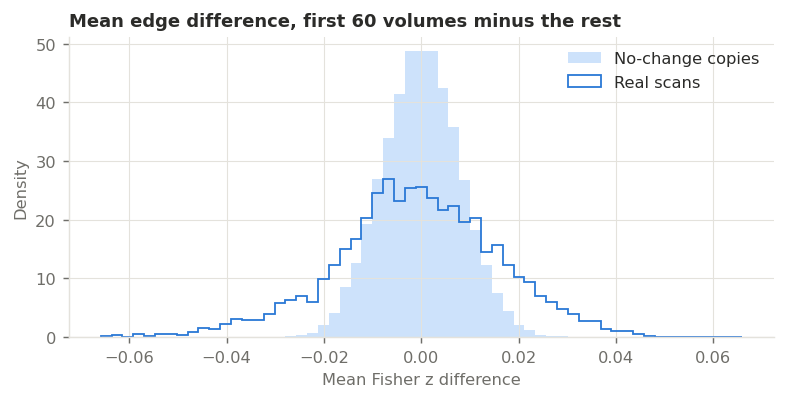

2026-10-31 00:37:14,685 DONE  scale_or_structure (12.4s)


In [7]:
def split_stats(x):
    first, rest = corr(x[:M]), corr(x[M:])
    eig_first = np.linalg.eigvalsh(first)[-1]
    eig_rest = np.linalg.eigvalsh(rest)[-1]
    return (fisher(first[UPPER]) - fisher(rest[UPPER]),
            np.abs(first[UPPER]).mean() - np.abs(rest[UPPER]).mean(), eig_first - eig_rest)


@step
def scale_or_structure():
    generator = np.random.default_rng(SEED + 1)
    real_d, null_d = [], [[] for _ in range(N_SURROGATES)]
    real_abs, null_abs, real_eig, null_eig = [], [], [], []
    mean_z = np.zeros(UPPER[0].size)
    for x in tqdm(LONG.values(), desc="split"):
        delta, abs_gap, eig_gap = split_stats(x)
        real_d.append(delta)
        real_abs.append(abs_gap)
        real_eig.append(eig_gap)
        mean_z += fisher(corr(x)[UPPER])
        for k in range(N_SURROGATES):
            d, a, e = split_stats(phase_randomise(x, generator))
            null_d[k].append(d)
            null_abs.append(a)
            null_eig.append(e)
    mean_z /= len(LONG)
    mean_real = np.mean(real_d, axis=0)
    mean_null = np.array([np.mean(d, axis=0) for d in null_d])
    limit = np.quantile(np.abs(mean_null), .999)
    RESULTS["scale_or_structure"] = {
        "scans": len(LONG),
        "rms_mean_edge_difference": {"real": float(np.sqrt((mean_real ** 2).mean())),
                                     "copies": float(np.sqrt((mean_null ** 2).mean()))},
        "share_edges_beyond_copies_99.9pct": float((np.abs(mean_real) > limit).mean()),
        "corr_with_mean_fnc": float(np.corrcoef(mean_real, mean_z)[0, 1]),
        "mean_abs_r_first_minus_rest": {"real": float(np.median(real_abs)), "copies": float(np.median(null_abs))},
        "lambda1_first_minus_rest": {"real": float(np.median(real_eig)), "copies": float(np.median(null_eig))},
    }
    print(json.dumps(RESULTS["scale_or_structure"], indent=1))

    fig, ax = plt.subplots(figsize=(7, 3))
    bins = np.linspace(-max(np.abs(mean_real)), max(np.abs(mean_real)), 60)
    ax.hist(mean_null.ravel(), bins=bins, density=True, color="#cde2fb", label="No-change copies")
    ax.hist(mean_real, bins=bins, density=True, histtype="step", color=BLUE, lw=2, label="Real scans")
    ax.set(title="Mean edge difference, first 60 volumes minus the rest", xlabel="Mean Fisher z difference", ylabel="Density")
    ax.legend()
    fig.savefig(FIG / "scale_or_structure.png")
    plt.show()
    plt.close(fig)

## 6. Noise floor for adjacent blocks

`||R_A - R_B||` is the jump size measured from data, in operator norm (WBSIP) and
Frobenius norm (Li & Li). The copies give its size with no change, which is the
empirical limit on what a block comparison can see.

Two positions are compared. `mid` puts both blocks around mid-scan. `start` puts
A in the first 60 volumes, which is what a monitor trained on the scan start
compares against, so a larger excess there would mean extra false alarms.
Clipping at 3 MAD shows how much of any excess comes from bursts. This is a
description, not a test, and an excess can be a slow fluctuation, not a jump.

In [8]:
def block_gap(x, length, position):
    start = 0 if position == "start" else len(x) // 2 - length
    gap = corr(x[start:start + length]) - corr(x[start + length:start + 2 * length])
    return np.abs(np.linalg.eigvalsh(gap)).max(), np.sqrt((gap ** 2).sum())


@step
def noise_floor():
    generator = np.random.default_rng(SEED + 2)
    rows = []
    for length, position in ((30, "mid"), (60, "mid"), (60, "start")):
        real, clipped, null, null_clipped = [], [], [], []
        for x in tqdm(LONG.values(), desc=f"{position} {length}"):
            real.append(block_gap(x, length, position))
            clipped.append(block_gap(despike(x), length, position))
            for _ in range(N_SURROGATES):
                s = phase_randomise(x, generator)
                null.append(block_gap(s, length, position))
                null_clipped.append(block_gap(despike(s), length, position))
        real, clipped, null, null_clipped = map(np.array, (real, clipped, null, null_clipped))
        for k, norm in enumerate(("op", "F")):
            limit = np.quantile(null[:, k], .95)
            limit_clipped = np.quantile(null_clipped[:, k], .95)
            rows.append({"block": length, "position": position, "norm": norm, "real_median": np.median(real[:, k]),
                         "copies_median": np.median(null[:, k]), "copies_q95": limit,
                         "share_real_above_q95": np.mean(real[:, k] > limit),
                         "clipped_real_median": np.median(clipped[:, k]),
                         "clipped_copies_median": np.median(null_clipped[:, k]),
                         "clipped_share_above_q95": np.mean(clipped[:, k] > limit_clipped)})
    table = pd.DataFrame(rows).round(3)
    RESULTS["noise_floor"] = table.to_dict("records")
    print(table.T.to_string())

2026-10-31 00:37:14,718 START noise_floor


mid 30:   0%|          | 0/678 [00:00<?, ?it/s]

mid 60:   0%|          | 0/678 [00:00<?, ?it/s]

start 60:   0%|          | 0/678 [00:00<?, ?it/s]

                              0       1       2       3       4       5
block                        30      30      60      60      60      60
position                    mid     mid     mid     mid   start   start
norm                         op       F      op       F      op       F
real_median              18.316  32.628  13.447  24.364  13.626  24.441
copies_median            16.513   30.24  11.527  21.563  11.444  21.484
copies_q95               24.132  37.909  17.454  27.517  16.872   27.33
share_real_above_q95      0.158   0.198   0.176    0.24   0.229   0.271
clipped_real_median      18.034  32.143   13.13  23.925  13.295  24.133
clipped_copies_median    16.517  30.257  11.517  21.577  11.449  21.496
clipped_share_above_q95   0.112   0.165   0.125   0.192   0.186   0.224
2026-10-31 00:38:01,051 DONE  noise_floor (46.3s)


## 7. What kind of effect is the structural difference at the scan start?

The first run found about 12% of edges differ on average between the first 60
volumes and the rest, so the quiet start is not only a shared scale. Two checks:

- **Scale per ICN:** a scalar s(t) means every ICN has the same variance ratio.
- **Time profile:** the pattern is estimated on half the scans, then tracked
  through the other half in sliding windows, which avoids circularity. A drop
  after the first windows means a start transient; a steady slope means a drift
  through the whole scan.

2026-10-31 00:38:01,113 START scale_per_icn
{
 "real_across_icns": {
  "q5": -0.2048,
  "q25": -0.139,
  "q50": -0.123,
  "q75": -0.1037,
  "q95": -0.0678
 },
 "copies_across_icns": {
  "q5": -0.0371,
  "q25": -0.0273,
  "q50": -0.0155,
  "q75": -0.0075,
  "q95": 0.0022
 },
 "share_icns_quieter_at_start": 1.0
}
2026-10-31 00:38:01,672 DONE  scale_per_icn (0.6s)
2026-10-31 00:38:01,674 START time_profile
{"fraction": [0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85], "real": [0.3964, 0.1803, 0.0884, -0.0013, -0.0666, -0.1264, -0.1187, -0.1669], "copies": [-0.1073, -0.0569, -0.0658, -0.0241, -0.0402, -0.0517, -0.0056, 0.0539]}


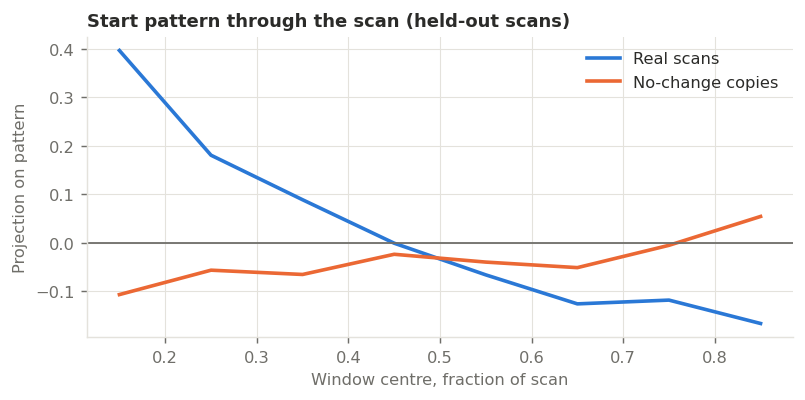

2026-10-31 00:38:07,877 DONE  time_profile (6.2s)


In [9]:
def variance_ratios(x):
    return np.log(x[:M].var(0, ddof=1) / x[M:].var(0, ddof=1))


@step
def scale_per_icn():
    generator = np.random.default_rng(SEED + 3)
    real = np.median([variance_ratios(x) for x in LONG.values()], axis=0)
    null = np.median([variance_ratios(phase_randomise(x, generator)) for x in LONG.values()], axis=0)
    RESULTS["scale_per_icn"] = {"real_across_icns": quantiles(real), "copies_across_icns": quantiles(null),
                                "share_icns_quieter_at_start": float((real < 0).mean())}
    print(json.dumps(RESULTS["scale_per_icn"], indent=1))


def window_profile(x, pattern, centres):
    base = fisher(corr(x)[UPPER])
    scale = (pattern ** 2).sum()
    values = []
    for fraction in centres:
        start = int(np.clip(fraction * len(x) - M / 2, 0, len(x) - M))
        values.append(((fisher(corr(x[start:start + M])[UPPER]) - base) * pattern).sum() / scale)
    return values


@step
def time_profile():
    generator = np.random.default_rng(SEED + 4)
    ids = np.array(sorted(LONG))
    rng.shuffle(ids)
    half = len(ids) // 2
    pattern = np.mean([split_stats(LONG[sid])[0] for sid in ids[:half]], axis=0)
    centres = np.linspace(.15, .85, 8)
    real = np.mean([window_profile(LONG[sid], pattern, centres) for sid in ids[half:]], axis=0)
    null = np.mean([window_profile(phase_randomise(LONG[sid], generator), pattern, centres) for sid in ids[half:]], axis=0)
    RESULTS["time_profile"] = {"fraction": np.round(centres, 3).tolist(), "real": np.round(real, 4).tolist(),
                               "copies": np.round(null, 4).tolist()}
    print(json.dumps(RESULTS["time_profile"]))

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(centres, real, color=BLUE, label="Real scans")
    ax.plot(centres, null, color=ORANGE, label="No-change copies")
    ax.axhline(0, color=MUTED, lw=1)
    ax.set(title="Start pattern through the scan (held-out scans)", xlabel="Window centre, fraction of scan", ylabel="Projection on pattern")
    ax.legend()
    fig.savefig(FIG / "time_profile.png")
    plt.show()
    plt.close(fig)

In [10]:
def as_json(value):
    if isinstance(value, (np.integer, np.bool_)):
        return value.item()
    if isinstance(value, np.floating):
        return float(value)
    return str(value)


@step
def finish():
    (WORK_ROOT / "01c-results.json").write_text(json.dumps(RESULTS, indent=1, default=as_json))
    log.info("sections failed: %s", RESULTS["sections_failed"] or "none")

2026-10-31 00:38:07,898 START finish
2026-10-31 00:38:07,900 sections failed: none
2026-10-31 00:38:07,901 DONE  finish (0.0s)
